# DISCRETE COONS PATCHES

In [1]:
import numpy as np

In [44]:

def discrete_coons_system(n, m, bs, alpha = -0.25):
    if n < 3 or m < 3:
        print('only boundary, no interior!')
        return
    # n ... # vrstic
    # m ... # stolpcev
    # bs ... slovar točk (i, j), 0 <= i <= n, 0 <= j <= m
    # alpha ... parameter za upoštevanje sosedov sistema, alpha + beta = 0.25 edini pogoj za njiju.
    
    beta = 0.25 - alpha
    
    # NOTRANJA tocka (i,j) se nanaša na stolpec in vrstico (i-1) * (m-1) + (j-1) v matriki A
    
    st_neznank = (n-1) * (m-1)
    
    A = np.eye((st_neznank))
    b = np.zeros((st_neznank, 1))
    
    # prva vrstica
    # tocke imajo pogoj glede na zgornji rob
    # trenutna vrstica je 0, j gre cez stolpce
    for j in range(1, m):
        # vmesne
        if j > 1 and j < (m-1):
            A[j-1, j-2] = -beta
            A[j-1, j] = -beta
            A[j-1, m-1+j-1] = -beta
            A[j-1, m-1+j-2] = -alpha
            A[j-1, m-1+j] = -alpha
            b[j-1] = alpha * bs[(0, j-1)] + beta * bs[(0, j)] + alpha * bs[(0, j+1)]
        
        # robni
        if j == 1:
            A[0, 1] = -beta
            A[0, m-1 + j-1] = -beta
            A[0, m + j-1] = -alpha
            b[j-1] = alpha * bs[(0, j-1)] + beta * bs[(0, j)] + alpha * bs[(0, j+1)] + beta * bs[(1, j-1)] + alpha * bs[(2, j-1)]
            
        if j == (m-1):
            A[m-2, m-3] = -beta
            A[m-2, m-1 + j-1] = -beta
            A[m-2, m-1 + j-2] = -alpha
            b[j-1] = alpha * bs[(0, j-1)] + beta * bs[(0, j)] + alpha * bs[(0, j+1)] + beta * bs[(1, j+1)] + alpha * bs[(2, j+1)]
            
    # zadnja vrstica
    # tocke imajo pogoj glede na spodnji rob
    # trenutna vrstica je n-2, j gre cez stolpce
    for j in range(1, m):
        # vmesne
        if j > 1 and j < (m-1):
            A[(n-2) * (m-1) + j-1, (n-2) * (m-1) + j-2] = -beta
            A[(n-2) * (m-1) + j-1, (n-2) * (m-1) + j] = -beta
            A[(n-2) * (m-1) + j-1, (n-3) * (m-1) + j-1] = -beta
            A[(n-2) * (m-1) + j-1, (n-3) * (m-1) + j-2] = -alpha
            A[(n-2) * (m-1) + j-1, (n-3) * (m-1) + j] = -alpha
            b[(n-2) * (m-1) + j-1] = alpha * bs[(n, j-1)] + beta * bs[(n, j)] + alpha * bs[(n, j+1)]
            
        # robni
        if j == 1:
            A[(n-2) * (m-1), (n-2) * (m-1) + 1] = -beta
            A[(n-2) * (m-1), (n-3) * (m-1)] = -beta
            A[(n-2) * (m-1), (n-3) * (m-1) + 1] = -alpha
            b[(n-2) * (m-1)] = alpha * bs[(n, 0)] + beta * bs[(n, 1)] + alpha * bs[(n, 2)] + beta * bs[(n-1, 0)] + alpha * bs[(n-2, 0)]
            
        if j == (m-1):
            A[(n-2) * (m-1) + j-1, (n-2) * (m-1) + j-2] = -beta
            A[(n-2) * (m-1) + j-1, (n-3) * (m-1) + j-1] = -beta
            A[(n-2) * (m-1) + j-1, (n-3) * (m-1) + j-2] = -alpha
            b[(n-2) * (m-1) + j-1] = alpha * bs[(n, j-1)] + beta * bs[(n, j)] + alpha * bs[(n, j+1)] + beta * bs[(n-1, j+1)] + alpha * bs[(n-2, j+1)]
     
    # prvi stolpec
    # tocke imajo pogoj glede na levi rob
    # trenutni stolpec je 0, i gre cez vrstice
    for i in range(2, n-1):
        A[(i-1) * (m-1), (i-2) * (m-1)] = -beta
        A[(i-1) * (m-1), i * (m-1)] = -beta
        A[(i-1) * (m-1), (i-1) * (m-1) + 1] = -beta
        A[(i-1) * (m-1), (i-2) * (m-1) + 1] = -alpha
        A[(i-1) * (m-1), i * (m-1) + 1] = -alpha
        b[(i-1) * (m-1)] = alpha * bs[(i-1, 0)] + beta * bs[(i, 0)] + alpha * bs[(i+1, 0)]

        # robnih ne potrebujemo, ker so ze v zgornjih
    
    # zadnji stolpec
    # tocke imajo pogoj glede na desni rob
    # trenutni stolpec je m-1, i gre cez vrstice
    for i in range(2, n-1):
        A[(i-1) * (m-1) + m-2, (i-2) * (m-1) + m-2] = -beta
        A[(i-1) * (m-1) + m-2, i * (m-1) + m-2] = -beta
        A[(i-1) * (m-1) + m-2, (i-1) * (m-1) + m-3] = -beta
        A[(i-1) * (m-1) + m-2, (i-2) * (m-1) + m-3] = -alpha
        A[(i-1) * (m-1) + m-2, i * (m-1) + m-3] = -alpha
        b[(i-1) * (m-1) + m-2] = alpha * bs[(i-1, m)] + beta * bs[(i, m)] + alpha * bs[(i+1, m)]

        # robnih ne potrebujemo, ker so ze v zgornjih
    
    # vmesne
    # samo notranje tocke
    for i in range(2, (n-1)):
        for j in range(2, (m-1)):
            # na mesta (i-1, j), (i+1, j), (i, j-1) in (i, j+1) damo -beta, na (i-1, j-1), (i-1, j+1), (i+1, j-1) in (i+1, j+1) damo -alpha
            # trenutna vrstica pa je (i-1) * (m-1) + (j-1)
            A[(i-1) * (m-1) + (j-1), (i-2) * (m-1) + j-1] = -beta
            A[(i-1) * (m-1) + (j-1), i * (m-1) + j-1] = -beta
            A[(i-1) * (m-1) + (j-1), (i-1) * (m-1) + j-2] = -beta
            A[(i-1) * (m-1) + (j-1), (i-1) * (m-1) + j] = -beta
            
            A[(i-1) * (m-1) + (j-1), (i-2) * (m-1) + j-2] = -alpha
            A[(i-1) * (m-1) + (j-1), (i-2) * (m-1) + j] = -alpha
            A[(i-1) * (m-1) + (j-1), i * (m-1) + j-2] = -alpha
            A[(i-1) * (m-1) + (j-1), i * (m-1) + j] = -alpha
           
    x = np.linalg.solve(A, b)
            
    return x

In [38]:
bs = {}
bs[(0, 0)] = 0
bs[(0, 1)] = 1
bs[(0, 2)] = 2
bs[(0, 3)] = 3
bs[(0, 4)] = 5

bs[(0, 0)] = 0
bs[(1, 0)] = 1
bs[(2, 0)] = 2
bs[(3, 0)] = 1
bs[(4, 0)] = 3

bs[(0, 4)] = 5
bs[(1, 4)] = 2
bs[(2, 4)] = 4
bs[(3, 4)] = 5
bs[(4, 4)] = 6

bs[(4, 0)] = 3
bs[(4, 1)] = 2
bs[(4, 2)] = 4
bs[(4, 3)] = 6
bs[(4, 4)] = 6

# boundary_points = {
#     'top': np.array([0, 1, 2, 3, 5]),    # b_0,j
#     'left': np.array([0, 1, 2, 1, 3]),   # b_i,0
#     'right': np.array([5, 2, 4, 5, 6])   # b_i,3
#     'bottom': np.array([3, 2, 4, 6, 6]), # b_3,j
# }

n = 4
m = 4
z = discrete_coons_system(n, m, bs)

cur = 0
for i in range(1, n):
    for j in range(1, m):
        bs[(i,j)] = z[cur][0]
        cur += 1


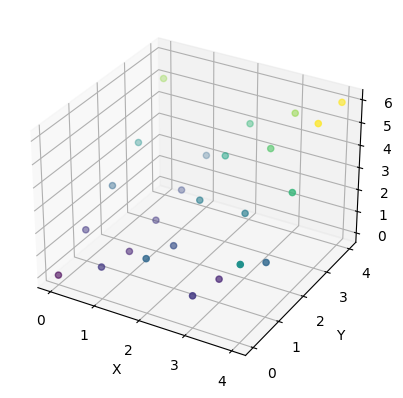

In [43]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Extract x, y, z coordinates from bs dictionary
x_coords = [key[0] for key in bs.keys()]
y_coords = [key[1] for key in bs.keys()]
z_coords = [value for value in bs.values()]

# Create a 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Scatter the points in 3D
ax.scatter(x_coords, y_coords, z_coords, c=z_coords, cmap='viridis')

# Plot the surface
# ax.plot_trisurf(x_coords, y_coords, z_coords, cmap='viridis')

# Set labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# plt.show()

plt.show(block=True)

In [20]:
import numpy as np

m, n = 4, 4

boundary_points = {
    'top': np.array([0, 1, 2, 3, 5]),    # b_0,j
    'bottom': np.array([3, 2, 4, 6, 6]), # b_3,j
    'left': np.array([0, 1, 2, 1, 3]),   # b_i,0
    'right': np.array([5, 2, 4, 5, 6])   # b_i,3
}

grid = np.zeros((m+1, n+1))
grid[0, :] = boundary_points['top']
grid[m, :] = boundary_points['bottom']
grid[:, 0] = boundary_points['left']
grid[:, n] = boundary_points['right']

def regular_coons_patch(m, n, grid):
    coons_patch = grid.copy()
    for i in range(1, m):
        for j in range(1, n):
            coons_patch[i, j] = (
                (1 - i/m) * grid[0, j] + (i/m) * grid[m, j] +
                (1 - j/n) * grid[i, 0] + (j/n) * grid[i, n] -
                (1 - i/m) * (1 - j/n) * grid[0, 0] - (1 - i/m) * (j/n) * grid[0, n] -
                (i/m) * (1 - j/n) * grid[m, 0] - (i/m) * (j/n) * grid[m, n]
            )
    return coons_patch

regular_patch = regular_coons_patch(m, n, grid.copy())

print(regular_patch)

[[0.    1.    2.    3.    5.   ]
 [1.    0.625 1.    1.375 2.   ]
 [2.    1.5   2.5   3.5   4.   ]
 [1.    0.625 2.5   4.375 5.   ]
 [3.    2.    4.    6.    6.   ]]


In [12]:
import numpy as np
from matplotlib import pyplot as plt
from itertools import product

In [40]:
%matplotlib inline

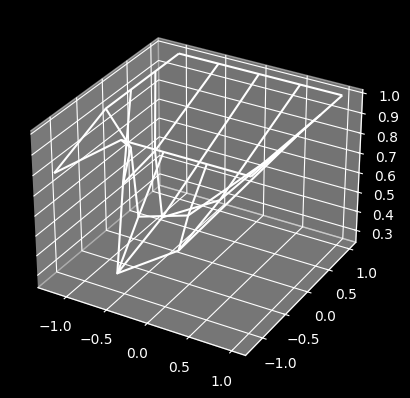

In [42]:
n = 5
m = 5

X, Y = np.meshgrid(np.linspace(-1, 1, m), np.linspace(-1, 1, n))
Z = np.ones_like(X)
# small perturbation
Z[0, 0] -= 0.2
X[0, 0] -= 0.2
Y[0, 0] -= 0.2

a = -0.37
b = 0.25 - a
mask = np.array([
    [a, b, a],
    [b,-1, b],
    [a, b, a]
])


def coons(points: np.ndarray, mask: np.ndarray):
    unknowns = (n-2)*(m-2)
    A = np.zeros((unknowns, unknowns))
    B = np.zeros(unknowns)

    cell_to_col = lambda i, j: (i-1)*(m-2) + (j-1)
    col_to_cell = lambda c: (c // (m-2) + 1, c % (m-2)+1)

    for i, j in product(range(1,m-1), range(1,n-1)):
        for x, y in product(range(-1, 2), repeat=2):
            k = mask[y+1, x+1]
            if 0 < i+y < m-1 and 0 < j+x < n-1:
                A[cell_to_col(i, j)][cell_to_col(i+y, j+x)] += k
            else:
                B[cell_to_col(i,j)] -= k * points[i+y, j+x]
    
    sol = np.linalg.solve(A, B).flatten()
    for c, s in enumerate(sol):
        i, j = col_to_cell(c)
        points[i, j] = s

coons(X, mask)
coons(Y, mask)
coons(Z, mask)

ax = plt.figure().add_subplot(projection='3d')
ax.plot_wireframe(X, Y, Z)